## Web Crawling & Analisis PageRank

Notebook ini melakukan empat hal secara berurutan:

1. **Crawling** – mulai dari URL seed, ambil semua tautan (`<a href>`), lalu kunjungi tautan itu secara berulang (BFS) sampai batas kedalaman tercapai.
2. **Membentuk graph** – tiap *website* (domain) menjadi **node**; jika halaman di website A memuat tautan ke website B, dibuat **edge A → B** (bobot = jumlah tautan).
3. **PageRank** – menghitung tingkat kepentingan tiap website: website yang ditautkan oleh banyak website penting akan mendapat skor tinggi.
4. **Visualisasi** – graph statis (matplotlib) dan graph interaktif (pyvis), plus tabel peringkat.

**Cara pakai:** jalankan sel dari atas ke bawah. Ubah parameter di bagian *2. Parameter* lalu jalankan ulang dari sel tersebut.

### 1. Instalasi & import
Jalankan sekali. Jika semua library sudah terpasang, sel instalasi bisa dilewati.

In [1]:
%pip install -q requests beautifulsoup4 networkx matplotlib pandas pyvis

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import csv, html, ipaddress, logging, os, socket, threading, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.parse import urldefrag, urljoin, urlparse
from urllib.robotparser import RobotFileParser

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import HTML, display

logging.basicConfig(level=logging.WARNING, format="%(message)s")
log = logging.getLogger("crawler")

USER_AGENT = "LabPageRankBot/1.0 (+penelitian laboratorium; web crawling & PageRank)"

SKIP_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".gif", ".svg", ".webp", ".ico", ".bmp",
    ".pdf", ".zip", ".rar", ".gz", ".tar", ".7z", ".exe", ".dmg", ".iso",
    ".mp3", ".mp4", ".avi", ".mkv", ".mov", ".wav",
    ".css", ".js", ".json", ".xml", ".rss", ".woff", ".woff2", ".ttf",
    ".doc", ".docx", ".xls", ".xlsx", ".ppt", ".pptx",
)
_MISSING = object()

### 2. Parameter
| Parameter | Arti |
|---|---|
| `SEEDS` | URL awal; boleh lebih dari satu |
| `DEPTH` | Seberapa jauh tautan diikuti (0 = hanya seed). Makin besar makin lama |
| `MAX_PAGES` | Batas total halaman yang dikunjungi |
| `PER_DOMAIN` | Batas halaman per website, agar tidak tersedot ke satu situs saja |
| `DELAY` | Jeda (detik) antar request ke website yang sama – supaya sopan & tidak diblokir |
| `MAX_SECONDS` | Batas waktu total crawl |
| `DAMPING` | Damping factor PageRank (umumnya 0.85) |

In [3]:
SEEDS = ["https://www.wikipedia.org"]

DEPTH = 2
MAX_PAGES = 100
PER_DOMAIN = 10
DELAY = 1.0
MAX_SECONDS = 180
RESPECT_ROBOTS = True
WEIGHTED = True      # True: bobot edge = jumlah tautan, False: semua bobot 1
DAMPING = 0.85

### 3. Fungsi URL
- `normalize_url` membersihkan URL (membuang `#fragment`, hanya `http/https`, melewati file gambar/PDF/dll).
- `get_domain` menentukan identitas "website" = hostname tanpa `www.`.
- `is_public_host` memblokir alamat lokal/privat (mencegah crawler dipakai memindai jaringan internal).

In [4]:
def normalize_url(url):
    """Buang fragment, hanya http/https, huruf kecil pada skema+host."""
    url, _ = urldefrag(url.strip())
    p = urlparse(url)
    if p.scheme not in ("http", "https") or not p.netloc:
        return None
    if p.path.lower().endswith(SKIP_EXTENSIONS):
        return None
    netloc = p.netloc.lower()
    path = p.path or "/"
    return p._replace(scheme=p.scheme.lower(), netloc=netloc, path=path).geturl()


def get_domain(url):
    """Identitas 'website' = hostname (tanpa www. dan tanpa port default)."""
    p = urlparse(url)
    host = (p.hostname or "").lower()
    if host.startswith("www."):
        host = host[4:]
    default = 443 if p.scheme == "https" else 80
    if p.port and p.port != default:
        host = f"{host}:{p.port}"
    return host


_public_cache = {}


def is_public_host(host):
    """False bila host mengarah ke alamat privat/loopback (cegah SSRF di server publik)."""
    host = host.split(":")[0]
    if host in _public_cache:
        return _public_cache[host]
    ok = False
    try:
        infos = socket.getaddrinfo(host, None)
        ok = all(ipaddress.ip_address(i[4][0]).is_global for i in infos)
    except (socket.gaierror, ValueError):
        ok = False
    _public_cache[host] = ok
    return ok

### 4. Class `Crawler`
Cara kerjanya (BFS per level):
1. Ambil seluruh halaman pada satu level secara paralel (`ThreadPoolExecutor`), dengan jeda per domain dan kepatuhan `robots.txt`.
2. Ekstrak semua tautan dari tiap halaman → simpan sebagai edge antar-domain di `self.edges`.
3. Tautan baru yang belum dikunjungi (dan belum melewati batas) menjadi level berikutnya.

In [5]:
class Crawler:
    def __init__(self, max_depth=2, max_pages=200, per_domain=20, delay=1.0,
                 timeout=10, workers=8, respect_robots=True,
                 max_bytes=2_000_000, block_private=True, max_seconds=None,
                 progress=None):
        self.max_depth = max_depth
        self.max_pages = max_pages
        self.per_domain = per_domain
        self.delay = delay
        self.timeout = timeout
        self.workers = workers
        self.respect_robots = respect_robots
        self.max_bytes = max_bytes
        self.block_private = block_private and not os.environ.get("CRAWLER_ALLOW_PRIVATE")
        self.deadline = None
        self.max_seconds = max_seconds
        self.progress = progress  # callback(level, selesai, total, pesan)
        self.page_titles = {}

        self.session = requests.Session()
        self.session.headers.update({"User-Agent": USER_AGENT})

        self._lock = threading.Lock()
        self._domain_locks = {}
        self._last_access = {}
        self._robots = {}

        # hasil
        self.edges = Counter()      # (domain_asal, domain_tujuan) -> jumlah tautan
        self.page_links = []        # (url_asal, url_tujuan)
        self.pages_crawled = Counter()  # domain -> jumlah halaman berhasil di-crawl
        self.domains = set()

    # ---- politeness -------------------------------------------------------
    def _throttle(self, domain):
        with self._lock:
            dlock = self._domain_locks.setdefault(domain, threading.Lock())
        with dlock:  # satu request per domain pada satu waktu + jeda
            wait = self.delay - (time.time() - self._last_access.get(domain, 0))
            if wait > 0:
                time.sleep(wait)
            self._last_access[domain] = time.time()

    def _allowed(self, url):
        if not self.respect_robots:
            return True
        p = urlparse(url)
        base = f"{p.scheme}://{p.netloc}"
        with self._lock:
            rp = self._robots.get(base, _MISSING)
        if rp is _MISSING:
            rp = RobotFileParser()
            try:
                r = self.session.get(base + "/robots.txt", timeout=self.timeout)
                if r.status_code == 200:
                    rp.parse(r.text.splitlines())
                else:
                    rp = None  # tidak ada robots.txt -> diizinkan
            except requests.RequestException:
                rp = None
            with self._lock:
                self._robots[base] = rp
        return True if rp is None else rp.can_fetch(USER_AGENT, url)

    # ---- fetch & parse ------------------------------------------------------
    def _fetch(self, url):
        """Kembalikan (url_akhir, daftar_tautan, judul) atau None bila gagal."""
        if self.deadline and time.time() > self.deadline:
            return None
        if self.block_private and not is_public_host(urlparse(url).hostname or ""):
            log.info("Alamat non-publik diblokir: %s", url)
            return None
        if not self._allowed(url):
            log.info("robots.txt melarang: %s", url)
            return None
        self._throttle(get_domain(url))
        try:
            with self.session.get(url, timeout=self.timeout, stream=True) as r:
                ctype = r.headers.get("Content-Type", "")
                if r.status_code != 200 or "html" not in ctype.lower():
                    return None
                content = r.raw.read(self.max_bytes, decode_content=True)
                encoding = r.encoding or "utf-8"
                final_url = r.url
            if self.block_private and not is_public_host(urlparse(final_url).hostname or ""):
                return None
        except requests.RequestException as e:
            log.warning("Gagal %s (%s)", url, e.__class__.__name__)
            return None

        soup = BeautifulSoup(content.decode(encoding, errors="replace"), "html.parser")
        title = soup.title.get_text(strip=True) if soup.title else ""
        base_tag = soup.find("base", href=True)
        base = urljoin(final_url, base_tag["href"]) if base_tag else final_url
        links = set()
        for a in soup.find_all("a", href=True):
            href = a["href"].strip()
            if href.lower().startswith(("mailto:", "javascript:", "tel:")):
                continue
            norm = normalize_url(urljoin(base, href))
            if norm:
                links.add(norm)
        return final_url, links, title

    def _fetch_level(self, frontier, depth):
        results = {}
        done = 0
        with ThreadPoolExecutor(max_workers=self.workers) as ex:
            futs = {ex.submit(self._fetch, u): u for u in frontier}
            for fut in as_completed(futs):
                u = futs[fut]
                try:
                    results[u] = fut.result()
                except Exception as e:  # satu halaman rusak tidak boleh menghentikan crawl
                    log.warning("Error %s: %s", u, e)
                    results[u] = None
                done += 1
                if self.progress:
                    self.progress(depth, done, len(frontier), u)
        return [results[u] for u in frontier]

    # ---- proses utama -----------------------------------------------------
    def crawl(self, seeds):
        seen = set()
        domain_scheduled = Counter()
        frontier = []
        for s in seeds:
            n = normalize_url(s if "://" in s else "https://" + s)
            if n and n not in seen:
                seen.add(n)
                domain_scheduled[get_domain(n)] += 1
                frontier.append(n)
                self.domains.add(get_domain(n))

        total_scheduled = len(frontier)
        if self.max_seconds:
            self.deadline = time.time() + self.max_seconds
        for depth in range(self.max_depth + 1):
            if not frontier:
                break
            log.info("=== Level %d: %d halaman ===", depth, len(frontier))
            results = self._fetch_level(frontier, depth)

            next_frontier = []
            for src_url, res in zip(frontier, results):
                if res is None:
                    continue
                final_url, links, title = res
                src = get_domain(src_url)
                self.page_titles[src_url] = title
                self.pages_crawled[src] += 1
                log.info("[d=%d] %s -> %d tautan", depth, src_url, len(links))
                for link in links:
                    dst = get_domain(link)
                    self.domains.add(dst)
                    self.page_links.append((src_url, link))
                    if dst != src:  # tautan antarwebsite saja
                        self.edges[(src, dst)] += 1
                    # jadwalkan untuk level berikutnya
                    if (depth < self.max_depth and link not in seen
                            and total_scheduled < self.max_pages
                            and domain_scheduled[dst] < self.per_domain):
                        seen.add(link)
                        domain_scheduled[dst] += 1
                        total_scheduled += 1
                        next_frontier.append(link)
            frontier = next_frontier

        log.info("Selesai: %d website, %d edge antarwebsite, %d halaman di-crawl",
                 len(self.domains), len(self.edges), sum(self.pages_crawled.values()))

### 5. Graph & algoritma PageRank
Rumus yang dipakai (power iteration):

$$PR(v) = \frac{1-d}{N} + d \left( \sum_{u \to v} \frac{PR(u)\,w(u,v)}{W(u)} + \frac{\text{dangling}}{N} \right)$$

- $d$ = damping factor, $N$ = jumlah website, $w(u,v)$ = bobot edge, $W(u)$ = total bobot tautan keluar dari $u$.
- *dangling* = total PageRank dari website yang tidak punya tautan keluar; dibagi rata ke semua website.
- Iterasi diulang sampai selisih antar iterasi sangat kecil (konvergen).

In [6]:
def build_graph(crawler, weighted=True):
    G = nx.DiGraph()
    G.add_nodes_from(crawler.domains)
    for (u, v), w in crawler.edges.items():
        G.add_edge(u, v, weight=w if weighted else 1)
    return G


def pagerank(G, damping=0.85, tol=1e-10, max_iter=200):
    """
    PageRank dengan power iteration:
        PR(v) = (1-d)/N + d * [ sum_{u->v} PR(u)*w(u,v)/W(u) + dangling/N ]
    dangling = total PR dari node tanpa tautan keluar (disebar merata).
    """
    nodes = list(G.nodes())
    n = len(nodes)
    if n == 0:
        return {}
    idx = {v: i for i, v in enumerate(nodes)}
    out_w = [sum(d.get("weight", 1) for _, _, d in G.out_edges(v, data=True)) for v in nodes]
    edges = [(idx[u], idx[v], d.get("weight", 1)) for u, v, d in G.edges(data=True)]

    pr = [1.0 / n] * n
    for it in range(1, max_iter + 1):
        dangling = sum(pr[i] for i in range(n) if out_w[i] == 0)
        base = (1 - damping) / n + damping * dangling / n
        new = [base] * n
        for u, v, w in edges:
            new[v] += damping * pr[u] * w / out_w[u]
        err = sum(abs(a - b) for a, b in zip(new, pr))
        pr = new
        if err < tol:
            log.info("PageRank konvergen pada iterasi %d (err=%.2e)", it, err)
            break
    return {nodes[i]: pr[i] for i in range(n)}

### 6. Jalankan crawling
Bagian ini yang memakan waktu. Pesan `Gagal ...` berarti ada halaman yang tidak bisa dijangkau — itu normal.

In [7]:
logging.getLogger("crawler").setLevel(logging.INFO)

crawler = Crawler(max_depth=DEPTH, max_pages=MAX_PAGES, per_domain=PER_DOMAIN,
                  delay=DELAY, respect_robots=RESPECT_ROBOTS, max_seconds=MAX_SECONDS,
                  progress=lambda lvl, done, total, url: print(f"\rLevel {lvl}: {done}/{total}", end=""))
crawler.crawl(SEEDS)
print()

=== Level 0: 1 halaman ===
[d=0] https://www.wikipedia.org/ -> 371 tautan
=== Level 1: 99 halaman ===


Level 1: 29/99

robots.txt melarang: https://foundation.wikimedia.org/wiki/Special:MyLanguage/Policy:Privacy_policy


Level 1: 35/99

robots.txt melarang: https://foundation.wikimedia.org/wiki/Special:MyLanguage/Policy:Donor_privacy_policy?uselang=en


Level 1: 46/99

robots.txt melarang: https://foundation.wikimedia.org/wiki/Special:MyLanguage/Policy:Terms_of_Use


Level 1: 98/99

[d=1] https://vep.wikipedia.org/ -> 293 tautan
[d=1] https://trv.wikipedia.org/ -> 409 tautan
[d=1] https://anp.wikipedia.org/ -> 691 tautan
[d=1] https://arc.wikipedia.org/ -> 503 tautan
[d=1] https://fiu-vro.wikipedia.org/ -> 500 tautan
[d=1] https://cdo.wikipedia.org/ -> 261 tautan
[d=1] https://en.wikipedia.org/wiki/List_of_Wikipedia_mobile_applications -> 356 tautan
[d=1] https://map-bms.wikipedia.org/ -> 587 tautan
[d=1] https://sg.wikipedia.org/ -> 556 tautan
[d=1] https://gcr.wikipedia.org/ -> 522 tautan
[d=1] https://av.wikipedia.org/ -> 950 tautan
[d=1] https://sl.wikipedia.org/ -> 294 tautan
[d=1] https://om.wikipedia.org/ -> 522 tautan
[d=1] https://zh-yue.wikipedia.org/ -> 315 tautan
[d=1] https://sr.wikipedia.org/ -> 335 tautan
[d=1] https://shi.wikipedia.org/ -> 515 tautan
[d=1] https://tum.wikipedia.org/ -> 581 tautan
[d=1] https://my.wikipedia.org/ -> 368 tautan
[d=1] https://be-tarask.wikipedia.org/ -> 188 tautan


Level 1: 99/99

[d=1] https://yi.wikipedia.org/ -> 619 tautan
[d=1] https://olo.wikipedia.org/ -> 474 tautan
[d=1] https://ig.wikipedia.org/ -> 167 tautan
[d=1] https://gpe.wikipedia.org/ -> 425 tautan
[d=1] https://hsb.wikipedia.org/ -> 211 tautan
[d=1] https://nv.wikipedia.org/ -> 146 tautan
[d=1] https://hr.wikipedia.org/ -> 529 tautan
[d=1] https://fa.wikipedia.org/ -> 438 tautan
[d=1] https://th.wikipedia.org/ -> 596 tautan
[d=1] https://lld.wikipedia.org/ -> 492 tautan
[d=1] https://nso.wikipedia.org/ -> 626 tautan
[d=1] https://jv.wikipedia.org/ -> 457 tautan
[d=1] https://bn.wikipedia.org/ -> 444 tautan
[d=1] https://kg.wikipedia.org/ -> 482 tautan
[d=1] https://pam.wikipedia.org/ -> 197 tautan
[d=1] https://diq.wikipedia.org/ -> 268 tautan
[d=1] https://ch.wikipedia.org/ -> 423 tautan
[d=1] https://lt.wikipedia.org/ -> 196 tautan
[d=1] https://mg.wikipedia.org/ -> 524 tautan
[d=1] https://war.wikipedia.org/ -> 592 tautan
[d=1] https://zh.wikipedia.org/ -> 595 tautan
[d=1] https://mag.wikipedi

### 7. Bangun graph & hitung PageRank
Hasil implementasi sendiri dibandingkan dengan `networkx.pagerank` sebagai validasi (selisih seharusnya sangat kecil).

In [8]:
G = build_graph(crawler, weighted=WEIGHTED)
assert G.number_of_nodes() > 0, "Tidak ada data. Coba seed lain / turunkan pembatasan."

pr = pagerank(G, damping=DAMPING)

ref = nx.pagerank(G, alpha=DAMPING, weight="weight", tol=1e-10)
print(f"Website: {G.number_of_nodes()} | Edge: {G.number_of_edges()} | "
      f"Selisih vs networkx: {max(abs(pr[n]-ref[n]) for n in pr):.2e}")

PageRank konvergen pada iterasi 9 (err=1.18e-11)


Website: 822 | Edge: 20938 | Selisih vs networkx: 5.30e-11


### 8. Tabel peringkat PageRank

In [9]:
df = pd.DataFrame([
    {"Peringkat": i, "Website": s, "PageRank": sc, "Tautan masuk": G.in_degree(s),
     "Tautan keluar": G.out_degree(s), "Halaman di-crawl": crawler.pages_crawled.get(s, 0)}
    for i, (s, sc) in enumerate(sorted(pr.items(), key=lambda x: -x[1]), 1)
])
print(f"🏆 Website terpenting: {df.iloc[0]['Website']} (PageRank {df.iloc[0]['PageRank']:.5f})")
df.head(20).style.format({"PageRank": "{:.5f}"}).bar(subset=["PageRank"], color="#a78bfa")

🏆 Website terpenting: foundation.wikimedia.org (PageRank 0.00460)


,Peringkat,Website,PageRank,Tautan masuk,Tautan keluar,Halaman di-crawl
0,1,foundation.wikimedia.org,0.00460,82,0,0
1,2,mediawiki.org,0.00336,81,0,0
2,3,commons.wikimedia.org,0.00256,81,0,0
3,4,wikidata.org,0.00253,81,0,0
4,5,meta.wikimedia.org,0.00247,79,32,1
5,6,species.wikimedia.org,0.00208,80,0,0
6,7,en.wikipedia.org,0.00206,78,61,1
7,8,apps.apple.com,0.00205,2,0,0
8,9,wikifunctions.org,0.00178,80,0,0
9,10,de.wikipedia.org,0.00174,77,0,0


### 9. Visualisasi graph (statis)
Ukuran & warna node = PageRank. Hanya website teratas yang diberi label agar tetap terbaca.

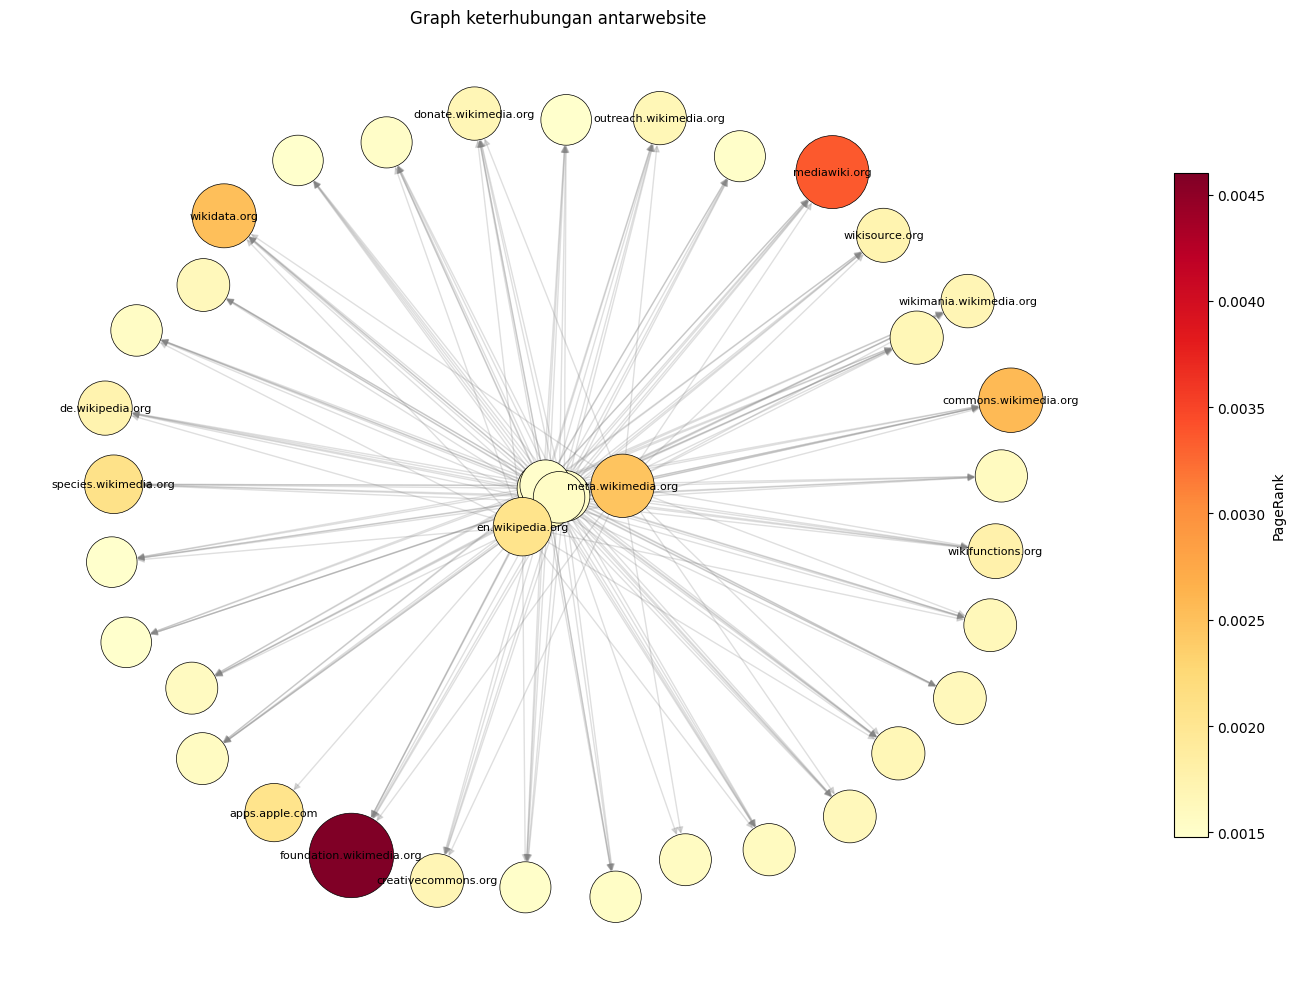

In [10]:
TOP_N = 40          # jumlah node yang digambar (berdasarkan PageRank tertinggi)
TOP_LABELS = 15     # jumlah node yang diberi label

keep = [n for n, _ in sorted(pr.items(), key=lambda x: -x[1])[:TOP_N]]
H = G.subgraph(keep)
vals = [pr[n] for n in H]
sizes = [200 + 3500 * v / max(vals) for v in vals]
labels = {n: n for n in keep[:TOP_LABELS]}

fig, ax = plt.subplots(figsize=(14, 10))
pos = nx.spring_layout(H, k=1.5 / (len(H) ** 0.5), seed=42, iterations=100)
nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.25, edge_color="gray", node_size=sizes, arrowsize=10)
nodes = nx.draw_networkx_nodes(H, pos, ax=ax, node_size=sizes, node_color=vals,
                               cmap=plt.cm.YlOrRd, edgecolors="black", linewidths=0.5)
nx.draw_networkx_labels(H, pos, labels=labels, font_size=8, ax=ax)
fig.colorbar(nodes, ax=ax, label="PageRank", shrink=0.7)
ax.set_title("Graph keterhubungan antarwebsite"); ax.axis("off")
plt.tight_layout(); plt.show()

### 10. Visualisasi graph (interaktif)
Bisa di-zoom, digeser, dan di-*hover* untuk melihat skor. Node kuning = website seed.

In [11]:
from pyvis.network import Network

seed_domains = {get_domain(normalize_url(s if "://" in s else "https://" + s)) for s in SEEDS}
vmax, vmin = max(pr[n] for n in H), min(pr[n] for n in H)

net = Network(height="650px", width="100%", directed=True, bgcolor="#0e1117",
              font_color="#e5e7eb", cdn_resources="in_line")
for n in H.nodes():
    t = (pr[n] - vmin) / ((vmax - vmin) or 1)
    net.add_node(n, label=n, size=14 + 40 * t,
                 color="#fbbf24" if n in seed_domains else "#a78bfa",
                 title=f"{n}\nPageRank: {pr[n]:.5f}")
for u, v, d in H.edges(data=True):
    net.add_edge(u, v, value=d.get("weight", 1))
net.set_options('{"physics": {"solver": "forceAtlas2Based", "forceAtlas2Based": {"gravitationalConstant": -70}}}')

page = net.generate_html(notebook=False)
display(HTML(f'<iframe srcdoc="{html.escape(page)}" width="100%" height="670" style="border:0"></iframe>'))

C:\Users\Chak_ko\AppData\Roaming\Python\Python312\site-packages\IPython\core\display.py:447: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


### 11. Website terkait dengan seed
Daftar website yang **ditautkan oleh** seed dan yang **menaut ke** seed, diurutkan berdasarkan PageRank.

In [12]:
for seed in seed_domains:
    if seed not in G:
        continue
    out_nb = sorted(G.successors(seed), key=lambda n: -pr[n])
    in_nb = sorted(G.predecessors(seed), key=lambda n: -pr[n])
    print(f"\n=== {seed} ===")
    print(f"Ditautkan oleh seed ({len(out_nb)}):", ", ".join(out_nb[:15]) or "-")
    print(f"Menaut ke seed ({len(in_nb)}):", ", ".join(in_nb[:15]) or "-")


=== wikipedia.org ===
Ditautkan oleh seed (366): foundation.wikimedia.org, mediawiki.org, commons.wikimedia.org, wikidata.org, meta.wikimedia.org, species.wikimedia.org, en.wikipedia.org, wikifunctions.org, de.wikipedia.org, wikisource.org, creativecommons.org, donate.wikimedia.org, ru.wikipedia.org, es.wikipedia.org, fr.wikipedia.org
Menaut ke seed (2): sc.wikipedia.org, wikibooks.org


### 12. Simpan hasil
Menyimpan peringkat dan daftar edge sebagai CSV di folder yang sama dengan notebook.

In [13]:
df.to_csv("pagerank.csv", index=False)
pd.DataFrame([{"sumber": u, "tujuan": v, "jumlah_tautan": c} for (u, v), c in crawler.edges.items()]) \
  .sort_values("jumlah_tautan", ascending=False).to_csv("edges.csv", index=False)
print("Tersimpan: pagerank.csv, edges.csv")

Tersimpan: pagerank.csv, edges.csv
